<a href="https://colab.research.google.com/github/dolaprogram-design/affinetune/blob/main/affinetune.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ติดตั้ง ExifTool ลงในระบบ Ubuntu ของ Colab
!apt-get install exiftool -y

# ติดตั้งไลบรารี Python สำหรับใช้งาน
!pip install -q pyexiftool rawpy opencv-python-headless matplotlib

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'libimage-exiftool-perl' instead of 'exiftool'
The following additional packages will be installed:
  libarchive-zip-perl libcompress-raw-lzma-perl libio-compress-brotli-perl
  libmime-charset-perl libsombok3 libunicode-linebreak-perl
Suggested packages:
  libposix-strptime-perl libencode-eucjpascii-perl libencode-hanextra-perl
  libpod2-base-perl
The following NEW packages will be installed:
  libarchive-zip-perl libcompress-raw-lzma-perl libimage-exiftool-perl
  libio-compress-brotli-perl libmime-charset-perl libsombok3
  libunicode-linebreak-perl
0 upgraded, 7 newly installed, 0 to remove and 0 not upgraded.
Need to get 4,196 kB of archives.
After this operation, 25.2 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 libarchive-zip-perl all 1.68-1 [90.2 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 libcompr

In [6]:
import os
import cv2
import rawpy
import numpy as np
import exiftool
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from google.colab import files

print("📤 กรุณาอัปโหลดไฟล์ RAW (.NEF) เพื่อทดสอบ:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"\n--- เริ่มต้นวิเคราะห์ไฟล์: {filename} ---")

    # ==========================================
    # ส่วนที่ 1: ดึงข้อมูล EXIF/MakerNotes และหาพิกัด AF กับขนาดรูปภาพจากกล้อง
    # ==========================================
    print("\n🔍 1. กำลังอ่านข้อมูล EXIF และ MakerNotes...")
    with exiftool.ExifToolHelper() as et:
        metadata = et.get_metadata(filename)[0]

    # ค้นหาค่าความละเอียดเซนเซอร์ที่ระบบ AF อ้างอิง
    af_image_width = metadata.get("MakerNotes:AFImageWidth", None)
    af_image_height = metadata.get("MakerNotes:AFImageHeight", None)

    # ค้นหาพิกัดตำแหน่ง AF Area Center
    af_x_coord = metadata.get("MakerNotes:AFAreaXPosition", None)
    af_y_coord = metadata.get("MakerNotes:AFAreaYPosition", None)

    print(f"   ▶ ข้อมูล AF จากกล้อง: ขนาดใช้อ้างอิง={af_image_width}x{af_image_height} | พิกัดจุดโฟกัสดิบ X={af_x_coord}, Y={af_y_coord}")

    # ==========================================
    # ส่วนที่ 2: แปลงภาพ RAW และคำนวณความคมชัดแบบแปรผันตามพิกัด
    # ==========================================
    print("\n🖼️ 2. กำลังแปลงไฟล์ RAW และคำนวณตามพิกัด AF ที่สเกลแล้ว...")
    try:
        # ถอดรหัสภาพ RAW แบบลดขนาดลงครึ่งนึง (Half-size)
        with rawpy.imread(filename) as raw:
            rgb_image = raw.postprocess(half_size=True)

        gray = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
        h, w = gray.shape

        # --- ตรรกะการแปลงและปรับพิกัด AF (Coordinate Scaling) ---
        if af_x_coord is not None and af_y_coord is not None and af_image_width is not None and af_image_height is not None:
            # คำนวณสเกลตามสัดส่วนความละเอียดจริงของภาพที่ประมวลผล เปรียบเทียบกับขนาดเต็มของกล้อง
            scale_x = w / float(af_image_width)
            scale_y = h / float(af_image_height)

            center_x = int(af_x_coord * scale_x)
            center_y = int(af_y_coord * scale_y)
            print(f"   ✅ สเกลพิกัด AF เรียบร้อย (ย่อลงตามขนาดรูปภาพ): Center X={center_x}, Y={center_y}")
        elif af_x_coord is not None and af_y_coord is not None:
            # Fallback หากไม่มีขนาดภาพอ้างอิง ให้หาร 2 ตามหลัก Half-size ทั่วไป
            center_x = int(af_x_coord) // 2
            center_y = int(af_y_coord) // 2
            print(f"   ⚠️ สเกลพิกัดโดยการหาร 2 (Default Half-size): Center X={center_x}, Y={center_y}")
        else:
            # Fallback ไปที่ศูนย์กลางภาพหากไม่พบพิกัดจุดโฟกัส
            center_x = w // 2
            center_y = h // 2
            print("   ⚠️ ไม่พบพิกัด AF Point กลับไปใช้จุดกึ่งกลางภาพแทน (Center Focus)")

        # กำหนดขนาดกรอบแบบไดนามิก (Dynamic Crop Box Size)
        # กำหนดขนาด 15% ของด้านที่สั้นที่สุดของภาพ (และตรวจสอบให้ได้เลขคู่)
        min_dim = min(h, w)
        box_size = int(min_dim * 0.15)
        if box_size % 2 != 0:
            box_size += 1

        half_box = box_size // 2
        print(f"   📐 ความละเอียดภาพที่ใช้วิเคราะห์: {w}x{h} | กำหนดขนาด Dynamic Box Size: {box_size}x{box_size} พิกเซล")

        # คำนวณขอบเขตกรอบป้องกันการหลุดขอบเขตภาพ (Boundary Check)
        start_x = max(0, center_x - half_box)
        end_x = min(w, center_x + half_box)
        start_y = max(0, center_y - half_box)
        end_y = min(h, center_y + half_box)

        # ตัดภาพเฉพาะบริเวณรอบจุดโฟกัส
        roi = gray[start_y:end_y, start_x:end_x]
        roi_rgb = rgb_image[start_y:end_y, start_x:end_x]

        # คำนวณความคมชัดด้วยวิธี Laplacian Variance
        laplacian = cv2.Laplacian(roi, cv2.CV_64F)
        score = np.var(laplacian)
        print(f"   🎯 คะแนนความคมชัด ณ จุด AF: {score:.2f}")

        # --- วาดกราฟฟิกเปรียบเทียบผลลัพธ์ ---
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

        # ภาพที่ 1: แสดงภาพเต็มพร้อมกรอบโฟกัส
        ax1.imshow(rgb_image)
        rect = patches.Rectangle((start_x, start_y), end_x - start_x, end_y - start_y,
                                 linewidth=2, edgecolor='r', facecolor='none')
        ax1.add_patch(rect)
        ax1.set_title("Original Image & Detected AF Box")
        ax1.axis('off')

        # ภาพที่ 2: ภาพพิกัดจุดโฟกัสที่ครอปมาประเมินคะแนน
        ax2.imshow(roi_rgb)
        ax2.set_title(f"Cropped AF Area\nSharpness Score: {score:.2f}")
        ax2.axis('off')

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"   ❌ เกิดข้อผิดพลาดในการประมวลผล: {e}")

📤 กรุณาอัปโหลดไฟล์ RAW (.NEF) เพื่อทดสอบ:


KeyboardInterrupt: 

In [5]:
import pandas as pd

if 'filename' in globals() and os.path.exists(filename):
    print(f"🔍 กำลังค้นหา Tags ที่เกี่ยวข้องกับการโฟกัส (AF / Focus) ในไฟล์: {filename}")
    with exiftool.ExifToolHelper() as et:
        metadata = et.get_metadata(filename)[0]

    tags_data = []
    for key, val in metadata.items():
        # กรองเฉพาะแท็กที่มีคำสำคัญเกี่ยวกับการโฟกัส
        key_lower = key.lower()
        if any(keyword in key_lower for keyword in ["af", "focus", "sharp", "point", "area", "zone"]):
            tags_data.append({"Tag Name": key, "Value": str(val)})

    df_tags = pd.DataFrame(tags_data)

    if not df_tags.empty:
        print(f"🎯 พบทั้งหมด {len(df_tags)} Tags ที่น่าจะเกี่ยวข้อง:")
        display(df_tags)
    else:
        print("❌ ไม่พบแท็กที่เกี่ยวกับการโฟกัสโดยตรง ลองเปลี่ยนคำค้นหาหลัก")
else:
    print("⚠️ ไม่พบข้อมูลไฟล์ภาพ กรุณารันเซลล์อัปโหลดไฟล์ด้านบนก่อนครับ")

🔍 กำลังค้นหา Tags ที่เกี่ยวข้องกับการโฟกัส (AF / Focus) ในไฟล์: PSJ_0890.NEF
🎯 พบทั้งหมด 42 Tags ที่น่าจะเกี่ยวข้อง:


,Tag Name,Value
0,EXIF:Sharpness,2
1,MakerNotes:FocusMode,AF-S
2,MakerNotes:Sharpness,24
3,MakerNotes:TimeZone,420
4,MakerNotes:AF-CPrioritySelection,0
5,MakerNotes:AF-SPrioritySelection,1
6,MakerNotes:AFPointSelection,1
7,MakerNotes:FocusTrackingLockOn,2
8,MakerNotes:AFActivation,1
9,MakerNotes:FocusPointWrap,0


--- เริ่มต้นวิเคราะห์ไฟล์อีกครั้ง: PSJ_0890.NEF ---
📸 ข้อมูลกล้อง: อ้างอิงขนาด 7360x4912 | จุดโฟกัสดิบ X=3680, Y=3736
🎯 พิกัด AF บนภาพจริง (หลังสเกล): X=1845, Y=1874
⚡ ความละเอียดวิเคราะห์: 3690x2464 | ขนาดกล่อง: 370x370
📈 Sharpness Score ณ จุดโฟกัส: 1404.21


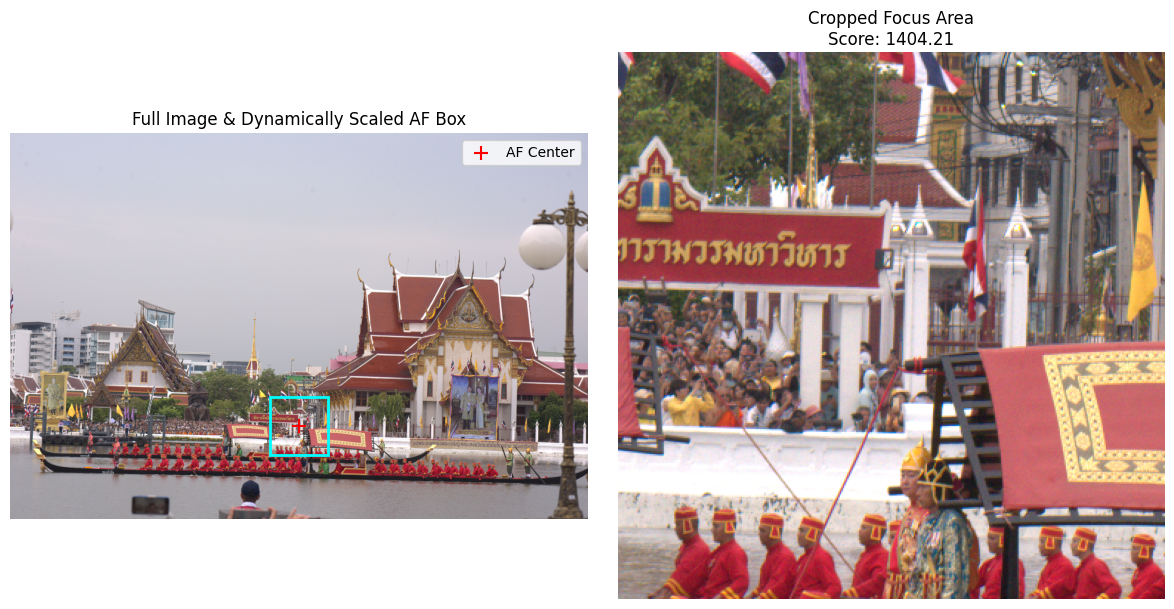

In [7]:
import os
import cv2
import rawpy
import numpy as np
import exiftool
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ใช้ไฟล์ล่าสุดที่มีอยู่ในหน่วยความจำ
test_filename = globals().get('filename', 'PSJ_0890.NEF')

if os.path.exists(test_filename):
    print(f"--- เริ่มต้นวิเคราะห์ไฟล์อีกครั้ง: {test_filename} ---")

    # 1. ดึงข้อมูลพิกัด AF และขนาดภาพเต็มจาก Metadata
    with exiftool.ExifToolHelper() as et:
        metadata = et.get_metadata(test_filename)[0]

    af_image_width = metadata.get("MakerNotes:AFImageWidth", None)
    af_image_height = metadata.get("MakerNotes:AFImageHeight", None)
    af_x_coord = metadata.get("MakerNotes:AFAreaXPosition", None)
    af_y_coord = metadata.get("MakerNotes:AFAreaYPosition", None)

    print(f"📸 ข้อมูลกล้อง: อ้างอิงขนาด {af_image_width}x{af_image_height} | จุดโฟกัสดิบ X={af_x_coord}, Y={af_y_coord}")

    # 2. แปลงภาพ RAW และคำนวณตามพิกัดที่สเกลจริง
    with rawpy.imread(test_filename) as raw:
        rgb_image = raw.postprocess(half_size=True)

    gray = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
    h, w = gray.shape

    # คำนวณอัตราส่วนย่อสเกลเพื่อหาพิกัดบนภาพจริง
    if af_x_coord is not None and af_y_coord is not None and af_image_width is not None and af_image_height is not None:
        scale_x = w / float(af_image_width)
        scale_y = h / float(af_image_height)
        center_x = int(af_x_coord * scale_x)
        center_y = int(af_y_coord * scale_y)
        print(f"🎯 พิกัด AF บนภาพจริง (หลังสเกล): X={center_x}, Y={center_y}")
    else:
        center_x = w // 2
        center_y = h // 2
        print("⚠️ ไม่พบพิกัดสเกล กลับไปใช้จุดศูนย์กลางภาพ")

    # กำหนดขนาดกล่องแบบ Dynamic (15% ของด้านที่สั้นที่สุด)
    min_dim = min(h, w)
    box_size = int(min_dim * 0.15)
    if box_size % 2 != 0:
        box_size += 1
    half_box = box_size // 2

    # ขอบเขตตารางครอป
    start_x = max(0, center_x - half_box)
    end_x = min(w, center_x + half_box)
    start_y = max(0, center_y - half_box)
    end_y = min(h, center_y + half_box)

    roi = gray[start_y:end_y, start_x:end_x]
    roi_rgb = rgb_image[start_y:end_y, start_x:end_x]

    # คำนวณหาคะแนนความคมชัด
    laplacian = cv2.Laplacian(roi, cv2.CV_64F)
    score = np.var(laplacian)
    print(f"⚡ ความละเอียดวิเคราะห์: {w}x{h} | ขนาดกล่อง: {box_size}x{box_size}")
    print(f"📈 Sharpness Score ณ จุดโฟกัส: {score:.2f}")

    # แสดงภาพผลลัพธ์
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    ax1.imshow(rgb_image)
    rect = patches.Rectangle((start_x, start_y), end_x - start_x, end_y - start_y,
                             linewidth=2, edgecolor='cyan', facecolor='none')
    ax1.add_patch(rect)
    ax1.scatter(center_x, center_y, color='red', marker='+', s=100, label='AF Center')
    ax1.set_title("Full Image & Dynamically Scaled AF Box")
    ax1.legend()
    ax1.axis('off')

    ax2.imshow(roi_rgb)
    ax2.set_title(f"Cropped Focus Area\nScore: {score:.2f}")
    ax2.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ ไม่พบไฟล์ภาพต้นฉบับในโฟลเดอร์ทำงาน กรุณารันเซลล์อัปโหลดใหม่อีกครั้งครับ")

In [8]:
import cv2
from google.colab import files

if 'roi_rgb' in globals() and roi_rgb is not None:
    # สร้างชื่อไฟล์ผลลัพธ์จากชื่อไฟล์ภาพต้นฉบับ
    base_name = os.path.splitext(test_filename)[0]
    output_filename = f"{base_name}_cropped_focus.jpg"

    # OpenCV คาดหวังสีแบบ BGR สำหรับบันทึกไฟล์ (imwrites) จึงต้องแปลงจาก RGB -> BGR
    roi_bgr = cv2.cvtColor(roi_rgb, cv2.COLOR_RGB2BGR)

    # บันทึกรูปภาพ
    cv2.imwrite(output_filename, roi_bgr)
    print(f"💾 บันทึกรูปภาพ ROI สำเร็จ: '{output_filename}'")

    # ทำการดาวน์โหลดภาพไปยังเครื่องคอมพิวเตอร์ของผู้ใช้
    print("📥 กำลังเริ่มดาวน์โหลดไฟล์ไปยังเครื่องของคุณ...")
    files.download(output_filename)
else:
    print("⚠️ ไม่พบตัวแปรภาพที่ครอป (roi_rgb) กรุณารันเซลล์วิเคราะห์รูปภาพด้านบนก่อน")

💾 บันทึกรูปภาพ ROI สำเร็จ: 'PSJ_0890_cropped_focus.jpg'
📥 กำลังเริ่มดาวน์โหลดไฟล์ไปยังเครื่องของคุณ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import os
import glob
import pandas as pd
import exiftool

# ค้นหาไฟล์ .NEF ทั้งหมดที่มีในโฟลเดอร์ปัจจุบัน
nef_files = glob.glob("*.NEF") + glob.glob("*.nef")

if nef_files:
    print(f"📊 กำลังสกัดรายละเอียดข้อมูลจากไฟล์ RAW ทั้งหมด ({len(nef_files)} ไฟล์)...")

    all_metadata_list = []
    with exiftool.ExifToolHelper() as et:
        for file_path in sorted(nef_files):
            try:
                meta = et.get_metadata(file_path)[0]
                # สกัดข้อมูลส่วนสำคัญที่จำเป็นต่อการวิเคราะห์และความคมชัด
                file_details = {
                    "File Name": os.path.basename(file_path),
                    "Camera Model": meta.get("EXIF:Model", "N/A"),
                    "Lens": meta.get("MakerNotes:LensSpec", meta.get("EXIF:LensModel", "N/A")),
                    "ISO": meta.get("EXIF:ISO", "N/A"),
                    "Aperture (F-Stop)": meta.get("EXIF:FNumber", "N/A"),
                    "Shutter Speed": meta.get("EXIF:ExposureTime", "N/A"),
                    "Focal Length": f'{meta.get("EXIF:FocalLength", "N/A")} mm',
                    "Focus Mode": meta.get("MakerNotes:FocusMode", "N/A"),
                    "AF Image Resolution": f'{meta.get("MakerNotes:AFImageWidth", "N/A")}x{meta.get("MakerNotes:AFImageHeight", "N/A")}',
                    "AF Point Raw Coord": f'X={meta.get("MakerNotes:AFAreaXPosition", "N/A")}, Y={meta.get("MakerNotes:AFAreaYPosition", "N/A")}',
                    "AF Box Dimensions": f'{meta.get("MakerNotes:AFAreaWidth", "N/A")}x{meta.get("MakerNotes:AFAreaHeight", "N/A")}',
                    "Focus Position (Steps)": meta.get("MakerNotes:FocusPosition", "N/A"),
                    "Focus Distance (m)": f'{meta.get("MakerNotes:FocusDistance", "N/A")}'
                }
                all_metadata_list.append(file_details)
            except Exception as e:
                print(f"⚠️ เกิดข้อผิดพลาดกับไฟล์ {file_path}: {e}")

    df_summary = pd.DataFrame(all_metadata_list)
    print("\n✨ ตารางสรุปรายละเอียดเชิงลึกของข้อมูลไฟล์ RAW:")
    display(df_summary)
else:
    print("⚠️ ไม่พบไฟล์ RAW (.NEF) ในโฟลเดอร์สำหรับดำเนินการสรุปข้อมูล")

📊 กำลังสกัดรายละเอียดข้อมูลจากไฟล์ RAW ทั้งหมด (3 ไฟล์)...

✨ ตารางสรุปรายละเอียดเชิงลึกของข้อมูลไฟล์ RAW:


,File Name,Camera Model,Lens,ISO,Aperture (F-Stop),Shutter Speed,Focal Length,Focus Mode,AF Image Resolution,AF Point Raw Coord,AF Box Dimensions,Focus Position (Steps),Focus Distance (m)
0,PSJ_0887.NEF,NIKON D810,N/A,450,8,0.0025,112 mm,AF-S,7360x4912,"X=3680, Y=3736",420x330,1,22.3872113856834
1,PSJ_0889.NEF,NIKON D810,N/A,450,8,0.0025,112 mm,AF-S,7360x4912,"X=3680, Y=3736",420x330,1,22.3872113856834
2,PSJ_0890.NEF,NIKON D810,N/A,450,8,0.0025,112 mm,AF-S,7360x4912,"X=3680, Y=3736",420x330,1,22.3872113856834


In [10]:
import os
import glob
import cv2
import rawpy
import numpy as np
import exiftool
import pandas as pd

# ค้นหาไฟล์ RAW ทั้งหมดที่มี
nef_files = sorted(glob.glob("*.NEF") + glob.glob("*.nef"))

sharpness_results = []

print("⚙️ กำลังประมวลผลคำนวณความคมชัด ณ จุดโฟกัสอ้างอิงรายไฟล์...")

with exiftool.ExifToolHelper() as et:
    for file_path in nef_files:
        try:
            filename = os.path.basename(file_path)

            # 1. ดึงข้อมูลพิกัดโฟกัสอ้างอิงจาก Metadata
            metadata = et.get_metadata(file_path)[0]
            af_image_width = metadata.get("MakerNotes:AFImageWidth", None)
            af_image_height = metadata.get("MakerNotes:AFImageHeight", None)
            af_x_coord = metadata.get("MakerNotes:AFAreaXPosition", None)
            af_y_coord = metadata.get("MakerNotes:AFAreaYPosition", None)

            # 2. ถอดรหัสภาพ RAW
            with rawpy.imread(file_path) as raw:
                rgb_image = raw.postprocess(half_size=True)

            gray = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
            h, w = gray.shape

            # 3. คำนวณพิกัดบนภาพย่อสเกล
            if af_x_coord is not None and af_y_coord is not None and af_image_width is not None and af_image_height is not None:
                scale_x = w / float(af_image_width)
                scale_y = h / float(af_image_height)
                center_x = int(af_x_coord * scale_x)
                center_y = int(af_y_coord * scale_y)
            else:
                center_x = w // 2
                center_y = h // 2

            # 4. กำหนดขนาดกล่องแปรผัน (Dynamic Box 15%)
            min_dim = min(h, w)
            box_size = int(min_dim * 0.15)
            if box_size % 2 != 0:
                box_size += 1
            half_box = box_size // 2

            # ขอบเขตครอปภาพ
            start_x = max(0, center_x - half_box)
            end_x = min(w, center_x + half_box)
            start_y = max(0, center_y - half_box)
            end_y = min(h, center_y + half_box)

            roi = gray[start_y:end_y, start_x:end_x]

            # 5. คำนวณหาคะแนน Laplacian Variance
            laplacian = cv2.Laplacian(roi, cv2.CV_64F)
            score = np.var(laplacian)

            sharpness_results.append({
                "File Name": filename,
                "Sharpness Score": round(score, 2),
                "AF Coordinates": f"({center_x}, {center_y})",
                "Box Size": f"{box_size}x{box_size}",
                "Focus Distance (m)": round(float(metadata.get("MakerNotes:FocusDistance", 0)), 2)
            })
            print(f"   ✅ {filename} ประมวลผลเสร็จสิ้น (คะแนน: {score:.2f})")

        except Exception as e:
            print(f"   ❌ เกิดข้อผิดพลาดกับไฟล์ {file_path}: {e}")

# แปลงเป็น DataFrame และแสดงผลแบบตารางที่จัดลำดับจากมากไปน้อย
if sharpness_results:
    df_comparison = pd.DataFrame(sharpness_results)
    df_comparison = df_comparison.sort_values(by="Sharpness Score", ascending=False).reset_index(drop=True)
    print("\n🏆 สรุปการเปรียบเทียบคะแนนความคมชัด (เรียงลำดับจากมากไปน้อย):")
    display(df_comparison)
else:
    print("⚠️ ไม่สามารถประมวลผลรูปภาพได้")

⚙️ กำลังประมวลผลคำนวณความคมชัด ณ จุดโฟกัสอ้างอิงรายไฟล์...
   ✅ PSJ_0887.NEF ประมวลผลเสร็จสิ้น (คะแนน: 310.62)
   ✅ PSJ_0889.NEF ประมวลผลเสร็จสิ้น (คะแนน: 705.56)
   ✅ PSJ_0890.NEF ประมวลผลเสร็จสิ้น (คะแนน: 1404.21)

🏆 สรุปการเปรียบเทียบคะแนนความคมชัด (เรียงลำดับจากมากไปน้อย):


,File Name,Sharpness Score,AF Coordinates,Box Size,Focus Distance (m)
0,PSJ_0890.NEF,1404.21,"(1845, 1874)",370x370,22.39
1,PSJ_0889.NEF,705.56,"(1845, 1874)",370x370,22.39
2,PSJ_0887.NEF,310.62,"(1845, 1874)",370x370,22.39


In [11]:
import os
import glob
import exiftool
import pandas as pd

# ค้นหาไฟล์ RAW
nef_files = sorted(glob.glob("*.NEF") + glob.glob("*.nef"))

if nef_files:
    print("🔍 กำลังสกัดและเปรียบเทียบการตั้งค่า AF Settings เชิงลึก...")

    af_compare_list = []
    with exiftool.ExifToolHelper() as et:
        for file_path in nef_files:
            try:
                meta = et.get_metadata(file_path)[0]
                filename = os.path.basename(file_path)

                # รวบรวมแท็กทั้งหมดที่เกี่ยวข้องกับระบบการทำงานของ Autofocus
                af_details = {
                    "File Name": filename,
                    "Focus Mode": meta.get("MakerNotes:FocusMode", "N/A").strip(),
                    "AF Area Mode": meta.get("MakerNotes:AFAreaMode", "N/A"),
                    "AF-C Priority": meta.get("MakerNotes:AF-CPrioritySelection", "N/A"),
                    "AF-S Priority": meta.get("MakerNotes:AF-SPrioritySelection", "N/A"),
                    "AF Point Selection": meta.get("MakerNotes:AFPointSelection", "N/A"),
                    "AF Fine Tune (On/Off)": meta.get("MakerNotes:AFFineTune", "N/A"),
                    "AF Fine Tune Index": meta.get("MakerNotes:AFFineTuneIndex", "N/A"),
                    "AF Fine Tune Adj": meta.get("MakerNotes:AFFineTuneAdj", "N/A"),
                    "Focus Position (Steps)": meta.get("MakerNotes:FocusPosition", "N/A"),
                    "Focus Distance (m)": round(float(meta.get("MakerNotes:FocusDistance", 0)), 2) if meta.get("MakerNotes:FocusDistance") else "N/A",
                    "Contrast Detect AF": meta.get("MakerNotes:ContrastDetectAF", "N/A"),
                    "Phase Detect AF": meta.get("MakerNotes:PhaseDetectAF", "N/A")
                }
                af_compare_list.append(af_details)
            except Exception as e:
                print(f"⚠️ ไม่สามารถประมวลผลไฟล์ {file_path}: {e}")

    df_af_compare = pd.DataFrame(af_compare_list)
    print("\n📊 ตารางเปรียบเทียบการตั้งค่าโฟกัส (AF Settings) เชิงลึก:")
    display(df_af_compare.T) # แสดงผลในแนวตั้ง (Transpose) เพื่อให้อ่านเปรียบเทียบได้ง่ายขึ้น
else:
    print("⚠️ ไม่พบไฟล์ RAW สำหรับวิเคราะห์")

🔍 กำลังสกัดและเปรียบเทียบการตั้งค่า AF Settings เชิงลึก...

📊 ตารางเปรียบเทียบการตั้งค่าโฟกัส (AF Settings) เชิงลึก:


,0,1,2
File Name,PSJ_0887.NEF,PSJ_0889.NEF,PSJ_0890.NEF
Focus Mode,AF-S,AF-S,AF-S
AF Area Mode,1,1,1
AF-C Priority,0,0,0
AF-S Priority,1,1,1
AF Point Selection,1,1,1
AF Fine Tune (On/Off),2,2,2
AF Fine Tune Index,255,255,255
AF Fine Tune Adj,-17,-17,-17
Focus Position (Steps),1,1,1


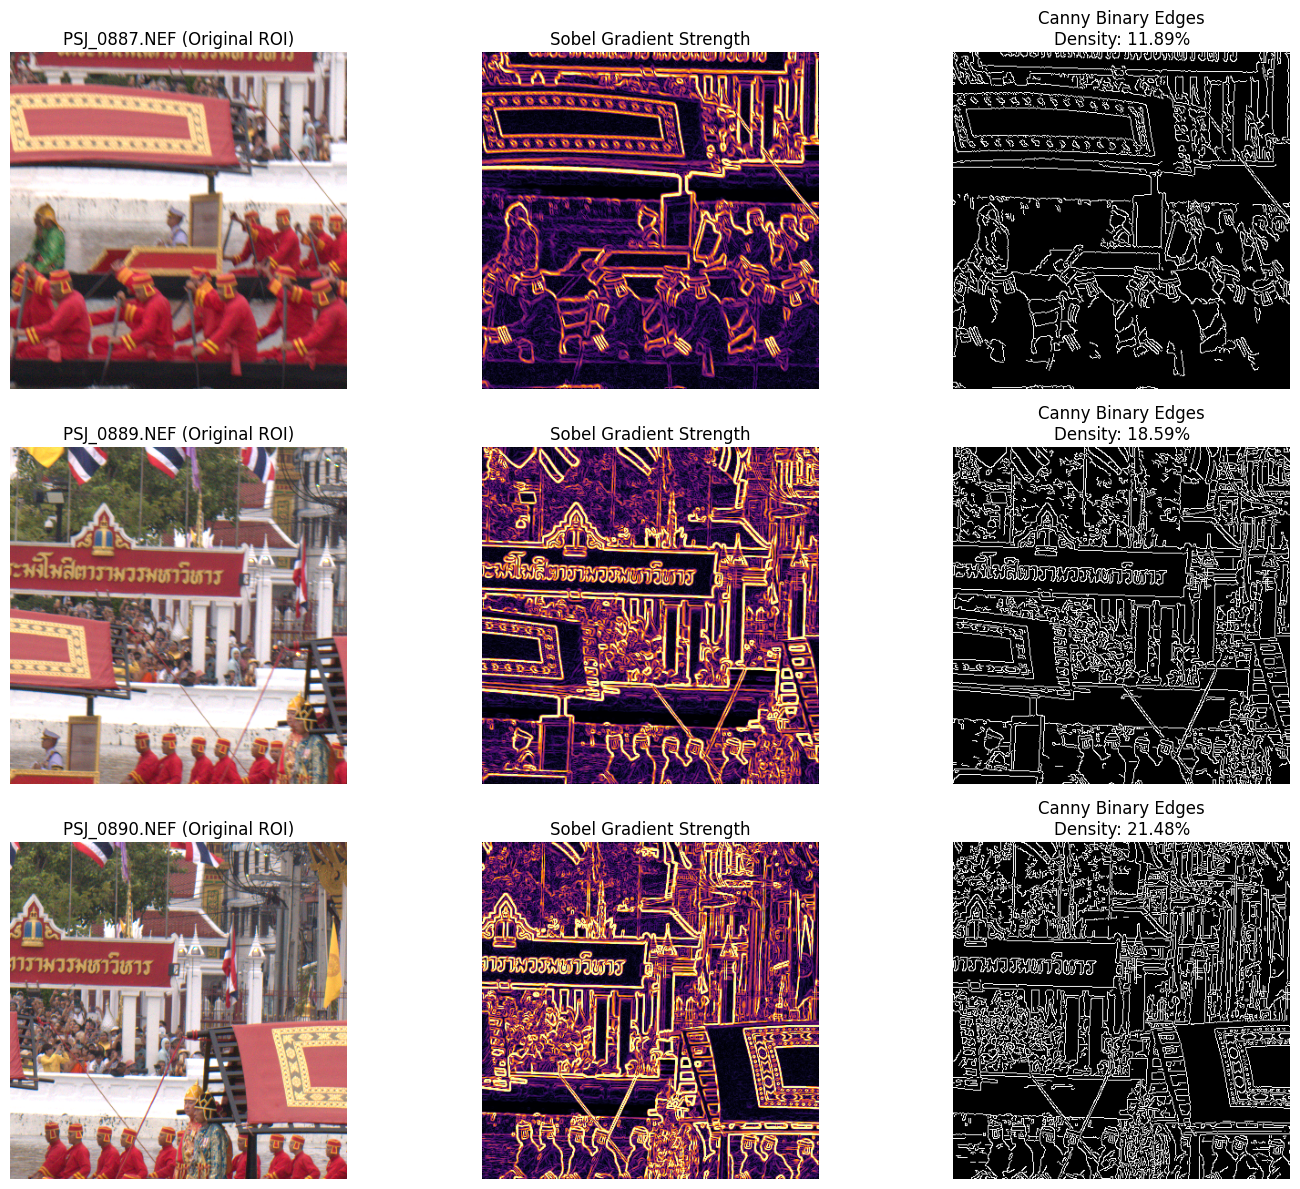


📊 ข้อมูลเปรียบเทียบเชิงลึกด้าน Edge Detection:


,File Name,Edge Density (%),Mean Gradient Strength
0,PSJ_0890.NEF,21.48,107.68
1,PSJ_0889.NEF,18.59,98.44
2,PSJ_0887.NEF,11.89,68.22


In [12]:
import os
import glob
import cv2
import rawpy
import numpy as np
import matplotlib.pyplot as plt
import exiftool

nef_files = sorted(glob.glob("*.NEF") + glob.glob("*.nef"))

fig, axes = plt.subplots(len(nef_files), 3, figsize=(15, 4 * len(nef_files)))
edge_density_results = []

with exiftool.ExifToolHelper() as et:
    for i, file_path in enumerate(nef_files):
        filename = os.path.basename(file_path)
        metadata = et.get_metadata(file_path)[0]

        # 1. โหลดและครอปภาพโฟกัส
        with rawpy.imread(file_path) as raw:
            rgb_image = raw.postprocess(half_size=True)
        gray = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
        h, w = gray.shape

        af_image_width = metadata.get("MakerNotes:AFImageWidth", None)
        af_image_height = metadata.get("MakerNotes:AFImageHeight", None)
        af_x_coord = metadata.get("MakerNotes:AFAreaXPosition", None)
        af_y_coord = metadata.get("MakerNotes:AFAreaYPosition", None)

        if af_x_coord is not None and af_y_coord is not None and af_image_width is not None and af_image_height is not None:
            scale_x = w / float(af_image_width)
            scale_y = h / float(af_image_height)
            center_x = int(af_x_coord * scale_x)
            center_y = int(af_y_coord * scale_y)
        else:
            center_x, center_y = w // 2, h // 2

        min_dim = min(h, w)
        box_size = int(min_dim * 0.15)
        if box_size % 2 != 0: box_size += 1
        half_box = box_size // 2

        start_x, end_x = max(0, center_x - half_box), min(w, center_x + half_box)
        start_y, end_y = max(0, center_y - half_box), min(h, center_y + half_box)

        roi_gray = gray[start_y:end_y, start_x:end_x]
        roi_rgb = rgb_image[start_y:end_y, start_x:end_x]

        # 2. ทำ Edge Detection (Sobel และ Canny)
        # Sobel เพื่อดูความเข้ม/ความเปรียบต่างของขอบภาพ
        sobel_x = cv2.Sobel(roi_gray, cv2.CV_64F, 1, 0, ksize=3)
        sobel_y = cv2.Sobel(roi_gray, cv2.CV_64F, 0, 1, ksize=3)
        sobel_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)
        sobel_normalized = np.uint8(np.clip(sobel_magnitude, 0, 255))

        # Canny เพื่อดูเส้นขอบแบบไบนารี
        # ใช้ Otsu's Thresholding หาเกณฑ์ความสว่างของขอบแบบอัตโนมัติ
        high_thresh, _ = cv2.threshold(roi_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        low_thresh = 0.5 * high_thresh
        canny_edges = cv2.Canny(roi_gray, low_thresh, high_thresh)

        # คำนวณหาความหนาแน่นของขอบ (Edge Density %)
        edge_pixel_count = np.sum(canny_edges > 0)
        total_pixel_count = canny_edges.size
        edge_density = (edge_pixel_count / total_pixel_count) * 100

        edge_density_results.append({
            "File Name": filename,
            "Edge Density (%)": round(edge_density, 2),
            "Mean Gradient Strength": round(np.mean(sobel_magnitude), 2)
        })

        # 3. พล็อตผลลัพธ์
        # คอลัมน์ 1: ภาพสี ROI
        axes[i, 0].imshow(roi_rgb)
        axes[i, 0].set_title(f"{filename} (Original ROI)")
        axes[i, 0].axis('off')

        # คอลัมน์ 2: Sobel Edge (Gradient Magnitude)
        axes[i, 1].imshow(sobel_normalized, cmap='inferno')
        axes[i, 1].set_title("Sobel Gradient Strength")
        axes[i, 1].axis('off')

        # คอลัมน์ 3: Canny Edge Detection
        axes[i, 2].imshow(canny_edges, cmap='gray')
        axes[i, 2].set_title(f"Canny Binary Edges\nDensity: {edge_density:.2f}%")
        axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

# แสดงตารางความหนาแน่นเชิงสถิติ
import pandas as pd
df_edges = pd.DataFrame(edge_density_results).sort_values(by="Mean Gradient Strength", ascending=False)
print("\n📊 ข้อมูลเปรียบเทียบเชิงลึกด้าน Edge Detection:")
display(df_edges.reset_index(drop=True))

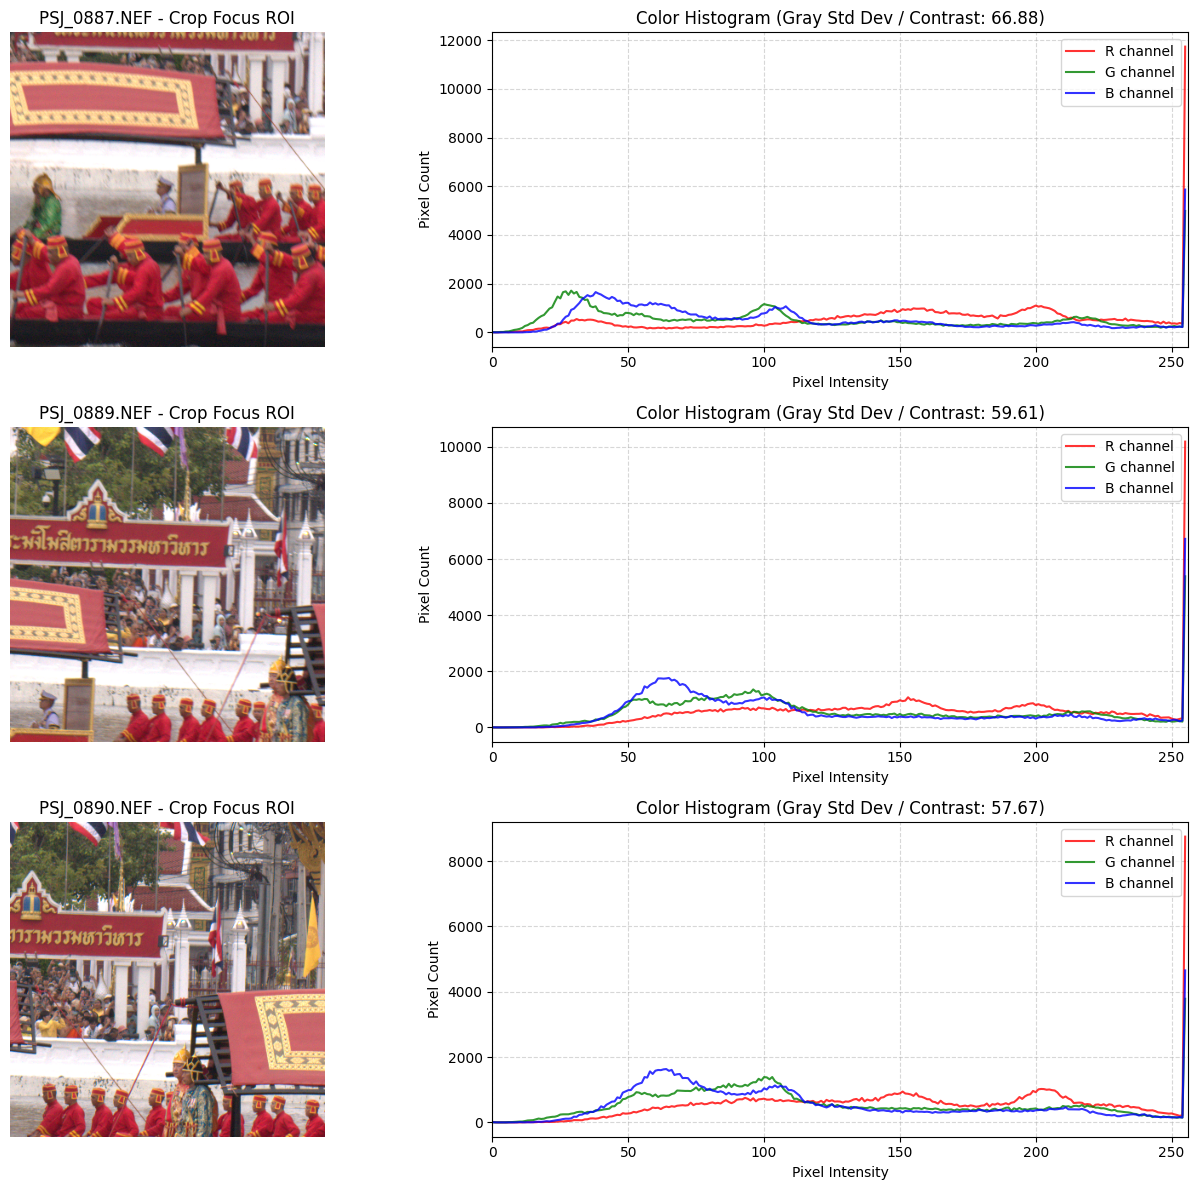

In [13]:
import os
import glob
import cv2
import rawpy
import numpy as np
import matplotlib.pyplot as plt
import exiftool

nef_files = sorted(glob.glob("*.NEF") + glob.glob("*.nef"))

# ตั้งค่ารูปกราฟเปรียบเทียบ
fig, axes = plt.subplots(len(nef_files), 2, figsize=(14, 4 * len(nef_files)))

with exiftool.ExifToolHelper() as et:
    for i, file_path in enumerate(nef_files):
        filename = os.path.basename(file_path)
        metadata = et.get_metadata(file_path)[0]

        # 1. โหลดภาพและคำนวณพิกัดจุดโฟกัส
        with rawpy.imread(file_path) as raw:
            rgb_image = raw.postprocess(half_size=True)
        h, w, _ = rgb_image.shape

        af_image_width = metadata.get("MakerNotes:AFImageWidth", None)
        af_image_height = metadata.get("MakerNotes:AFImageHeight", None)
        af_x_coord = metadata.get("MakerNotes:AFAreaXPosition", None)
        af_y_coord = metadata.get("MakerNotes:AFAreaYPosition", None)

        if af_x_coord is not None and af_y_coord is not None and af_image_width is not None and af_image_height is not None:
            scale_x = w / float(af_image_width)
            scale_y = h / float(af_image_height)
            center_x = int(af_x_coord * scale_x)
            center_y = int(af_y_coord * scale_y)
        else:
            center_x, center_y = w // 2, h // 2

        min_dim = min(h, w)
        box_size = int(min_dim * 0.15)
        if box_size % 2 != 0: box_size += 1
        half_box = box_size // 2

        start_x, end_x = max(0, center_x - half_box), min(w, center_x + half_box)
        start_y, end_y = max(0, center_y - half_box), min(h, center_y + half_box)

        roi_rgb = rgb_image[start_y:end_y, start_x:end_x]

        # 2. พล็อตคอลัมน์แรก: ภาพสี ROI
        axes[i, 0].imshow(roi_rgb)
        axes[i, 0].set_title(f"{filename} - Crop Focus ROI")
        axes[i, 0].axis('off')

        # 3. พล็อตคอลัมน์สอง: กราฟ RGB Histogram
        colors = ('r', 'g', 'b')
        for j, col in enumerate(colors):
            # คำนวณหาฮิสโตแกรมของแต่ละสี
            hist = cv2.calcHist([roi_rgb], [j], None, [256], [0, 256])
            axes[i, 1].plot(hist, color=col, label=f'{col.upper()} channel', alpha=0.8, linewidth=1.5)

        # คำนวณหาความต่างสีและเบี่ยงเบนมาตรฐาน (Standard Deviation) ของภาพเกรย์สเกลใน ROI เพื่อวัดคอนทราสต์ทางสถิติ
        roi_gray = cv2.cvtColor(roi_rgb, cv2.COLOR_RGB2GRAY)
        std_val = np.std(roi_gray)

        axes[i, 1].set_title(f"Color Histogram (Gray Std Dev / Contrast: {std_val:.2f})")
        axes[i, 1].set_xlim([0, 256])
        axes[i, 1].set_xlabel("Pixel Intensity")
        axes[i, 1].set_ylabel("Pixel Count")
        axes[i, 1].grid(True, linestyle='--', alpha=0.5)
        axes[i, 1].legend(loc='upper right')

plt.tight_layout()
plt.show()

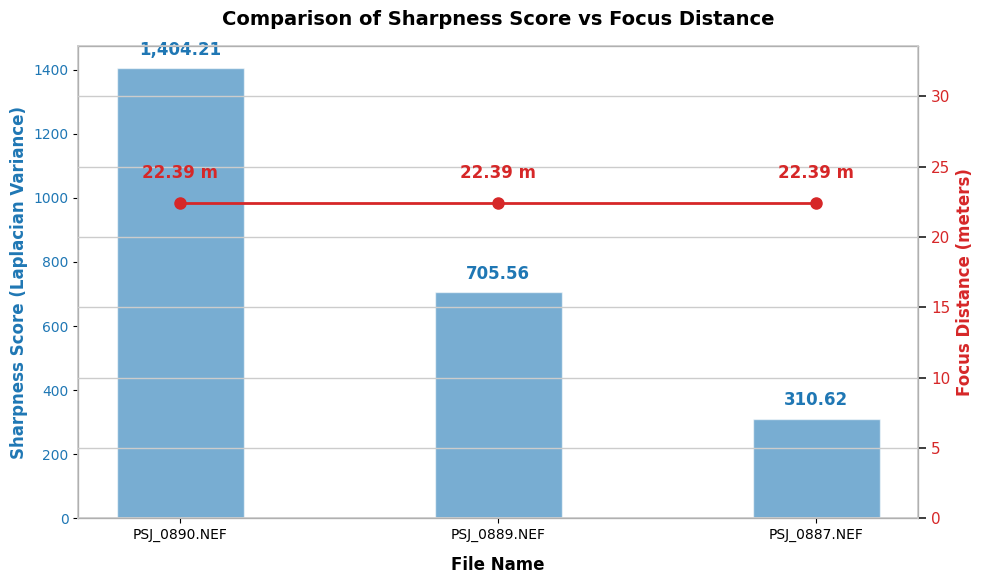

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# ใช้ข้อมูลจาก DataFrame df_comparison ที่มีอยู่แล้ว
if 'df_comparison' in globals() and not df_comparison.empty:
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # ตั้งค่าธีมเพื่อความสวยงาม
    sns.set_theme(style="whitegrid")

    # 1. พล็อตกราฟแท่งแสดงคะแนนความคมชัด (Sharpness Score)
    color = 'tab:blue'
    ax1.set_xlabel('File Name', fontsize=12, fontweight='bold', labelpad=10)
    ax1.set_ylabel('Sharpness Score (Laplacian Variance)', color=color, fontsize=12, fontweight='bold')
    bars = ax1.bar(df_comparison['File Name'], df_comparison['Sharpness Score'], color=color, alpha=0.6, width=0.4, label='Sharpness Score')
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.set_title('Comparison of Sharpness Score vs Focus Distance', fontsize=14, fontweight='bold', pad=15)

    # ใส่ตัวเลขคะแนนบนกราฟแท่ง
    for bar in bars:
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 30, f'{yval:,.2f}', ha='center', va='bottom', color=color, fontweight='bold')

    # 2. สร้างแกน Y ฝั่งขวา (Twin Axis) เพื่อพล็อตกราฟเส้น/จุดระยะโฟกัส (Focus Distance)
    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('Focus Distance (meters)', color=color, fontsize=12, fontweight='bold')
    line = ax2.plot(df_comparison['File Name'], df_comparison['Focus Distance (m)'], color=color, marker='o', linewidth=2, markersize=8, label='Focus Distance (m)')
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.set_ylim(0, max(df_comparison['Focus Distance (m)']) * 1.5) # ปรับสเกลให้อ่านง่าย

    # ใส่ตัวเลขระยะทางโฟกัสเหนือจุดพล็อต
    for idx, row in df_comparison.iterrows():
        ax2.text(row['File Name'], row['Focus Distance (m)'] + 1.5, f"{row['Focus Distance (m)']:.2f} m", ha='center', va='bottom', color=color, fontweight='bold')

    fig.tight_layout()
    plt.show()
else:
    print("⚠️ ไม่พบข้อมูลความคมชัดของรูปภาพในหน่วยความจำ กรุณารันขั้นตอนวิเคราะห์คะแนนความคมชัดก่อนครับ")

📊 ตารางข้อมูลเปรียบเทียบระหว่าง Sharpness Score และ Edge Density (%):


,File Name,Sharpness Score,Edge Density (%),Mean Gradient Strength
0,PSJ_0890.NEF,1404.21,21.48,107.68
1,PSJ_0889.NEF,705.56,18.59,98.44
2,PSJ_0887.NEF,310.62,11.89,68.22



🎯 ค่าสหสัมพันธ์ (Pearson Correlation Coefficient): 0.9270
💡 ผลลัพธ์: มีความสัมพันธ์เชิงบวกในระดับที่สูงมาก (Strong Positive Correlation) ซึ่งหมายความว่า ค่าความคมชัดแบบ Laplacian แปรผันตรงกับความหนาแน่นของขอบที่ตรวจจับได้อย่างสอดคล้องกันเป็นอย่างดี


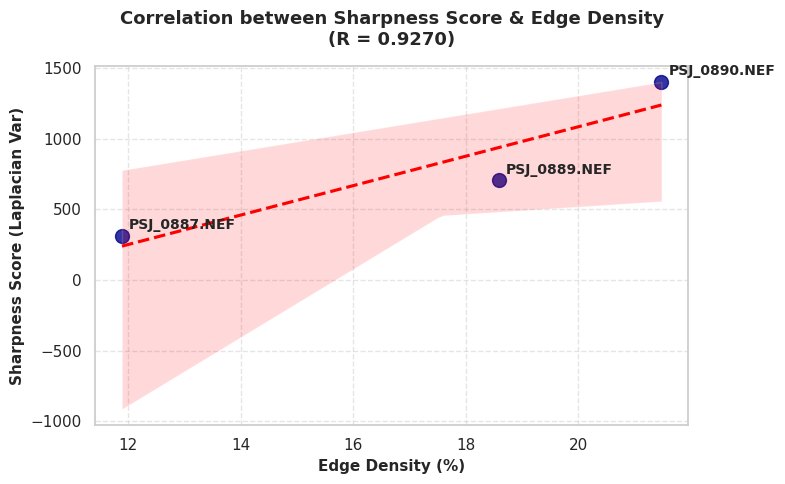

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ตรวจสอบความพร้อมของข้อมูล
if 'df_comparison' in globals() and 'df_edges' in globals():
    # รวม DataFrame เข้าด้วยกันโดยใช้ File Name เป็นคีย์
    df_merged = pd.merge(df_comparison, df_edges, on="File Name")

    # คำนวณค่าสหสัมพันธ์ Pearson Correlation
    correlation = df_merged['Sharpness Score'].corr(df_merged['Edge Density (%)'])

    print("📊 ตารางข้อมูลเปรียบเทียบระหว่าง Sharpness Score และ Edge Density (%):")
    display(df_merged[['File Name', 'Sharpness Score', 'Edge Density (%)', 'Mean Gradient Strength']])
    print(f"\n🎯 ค่าสหสัมพันธ์ (Pearson Correlation Coefficient): {correlation:.4f}")
    if correlation > 0.8:
         print("💡 ผลลัพธ์: มีความสัมพันธ์เชิงบวกในระดับที่สูงมาก (Strong Positive Correlation) ซึ่งหมายความว่า ค่าความคมชัดแบบ Laplacian แปรผันตรงกับความหนาแน่นของขอบที่ตรวจจับได้อย่างสอดคล้องกันเป็นอย่างดี")
    elif correlation > 0.5:
         print("💡 ผลลัพธ์: มีความสัมพันธ์เชิงบวกในระดับปานกลาง")
    else:
         print("💡 ผลลัพธ์: มีความสัมพันธ์ค่อนข้างน้อย")

    # พล็อตกราฟแสดงความสัมพันธ์เชิงเส้น (Regression Plot)
    plt.figure(figsize=(8, 5))
    sns.regplot(data=df_merged, x='Edge Density (%)', y='Sharpness Score',
                scatter_kws={'s': 100, 'color': 'darkblue'}, line_kws={'color': 'red', 'linestyle': '--'})

    # ใส่ชื่อไฟล์กำกับแต่ละจุด
    for i, txt in enumerate(df_merged['File Name']):
        plt.annotate(txt, (df_merged['Edge Density (%)'].iloc[i], df_merged['Sharpness Score'].iloc[i]),
                     xytext=(5, 5), textcoords='offset points', fontsize=10, fontweight='bold')

    plt.title(f'Correlation between Sharpness Score & Edge Density\n(R = {correlation:.4f})', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Edge Density (%)', fontsize=11, fontweight='bold')
    plt.ylabel('Sharpness Score (Laplacian Var)', fontsize=11, fontweight='bold')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ ไม่พบข้อมูลสำหรับใช้คำนวณค่าสหสัมพันธ์ กรุณาตรวจสอบว่ามีตัวแปร df_comparison และ df_edges ในระบบครบถ้วนแล้ว")

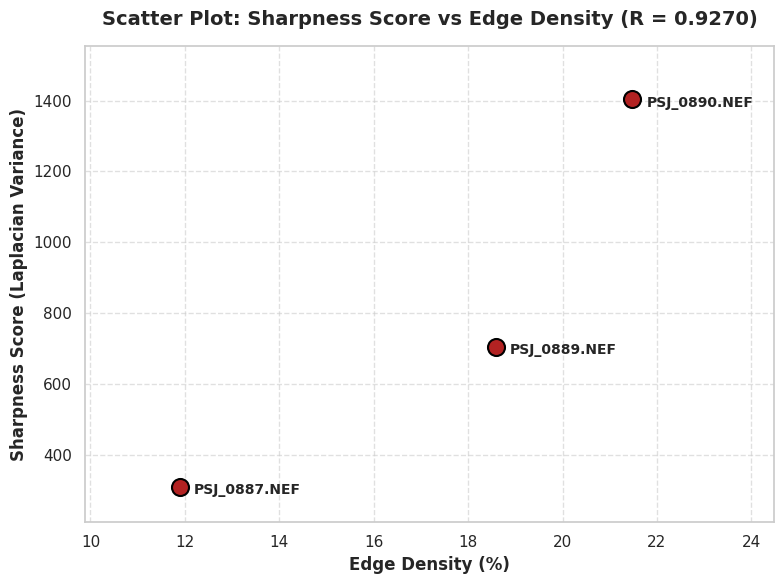

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'df_merged' in globals() and not df_merged.empty:
    plt.figure(figsize=(8, 6))
    sns.set_theme(style="whitegrid")

    # สร้างกราฟ Scatter Plot
    scatter = sns.scatterplot(
        data=df_merged,
        x='Edge Density (%)',
        y='Sharpness Score',
        s=150,
        color='firebrick',
        edgecolor='black',
        linewidth=1.5,
        zorder=3
    )

    # ใส่ป้ายกำกับชื่อไฟล์ให้กับแต่ละจุดพล็อต
    for i in range(len(df_merged)):
        plt.text(
            df_merged['Edge Density (%)'].iloc[i] + 0.3,
            df_merged['Sharpness Score'].iloc[i] - 10,
            df_merged['File Name'].iloc[i],
            fontsize=10,
            fontweight='bold',
            va='center'
        )

    # คำนวณค่า R สหสัมพันธ์เชิงเส้น
    r_val = df_merged['Sharpness Score'].corr(df_merged['Edge Density (%)'])

    plt.title(f'Scatter Plot: Sharpness Score vs Edge Density (R = {r_val:.4f})', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Edge Density (%)', fontsize=12, fontweight='bold')
    plt.ylabel('Sharpness Score (Laplacian Variance)', fontsize=12, fontweight='bold')

    # ขยายช่วงแกน X และ Y เล็กน้อยเพื่อให้เห็นจุดและชื่อไฟล์ได้ชัดเจนขึ้น ไม่หลุดขอบ
    plt.xlim(df_merged['Edge Density (%)'].min() - 2, df_merged['Edge Density (%)'].max() + 3)
    plt.ylim(df_merged['Sharpness Score'].min() - 100, df_merged['Sharpness Score'].max() + 150)

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ ไม่พบข้อมูลสำหรับพล็อตกราฟ Scatter Plot กรุณารันเซลล์วิเคราะห์ก่อนหน้าก่อนครับ")

In [17]:
import pandas as pd

# ตรวจสอบความพร้อมของข้อมูลจากหน่วยความจำ
if 'df_comparison' in globals() and 'df_af_compare' in globals():
    # รวมตารางข้อมูลคะแนนความคมชัดกับการตั้งค่า AF
    df_analysis = pd.merge(
        df_comparison[['File Name', 'Sharpness Score', 'Focus Distance (m)']],
        df_af_compare[['File Name', 'AF Fine Tune (On/Off)', 'AF Fine Tune Index', 'AF Fine Tune Adj', 'Focus Position (Steps)']],
        on='File Name'
    )

    print("📊 ตารางเปรียบเทียบผลกระทบของ AF Fine Tune Adj ต่อ Sharpness Score:")
    display(df_analysis)
else:
    print("⚠️ ไม่พบข้อมูลที่จำเป็นในหน่วยความจำ")

📊 ตารางเปรียบเทียบผลกระทบของ AF Fine Tune Adj ต่อ Sharpness Score:


,File Name,Sharpness Score,Focus Distance (m),AF Fine Tune (On/Off),AF Fine Tune Index,AF Fine Tune Adj,Focus Position (Steps)
0,PSJ_0890.NEF,1404.21,22.39,2,255,-17,1
1,PSJ_0889.NEF,705.56,22.39,2,255,-17,1
2,PSJ_0887.NEF,310.62,22.39,2,255,-17,1


In [18]:
import pandas as pd

if 'df_summary' in globals() and not df_summary.empty:
    # เลือกคอลัมน์พารามิเตอร์กล้องอื่น ๆ เพื่อนำมาวิเคราะห์เปรียบเทียบ
    cols_to_analyze = [
        'File Name', 'Camera Model', 'ISO', 'Aperture (F-Stop)',
        'Shutter Speed', 'Focal Length', 'AF Box Dimensions'
    ]

    df_subset = df_summary[cols_to_analyze].copy()

    print("📊 ตารางพารามิเตอร์การรับแสงและกล้องเพิ่มเติม:")
    display(df_subset)

    # แสดงบทวิเคราะห์ทางสถิติของพารามิเตอร์
    print("\n🔍 สรุปการเปรียบเทียบพารามิเตอร์อื่น ๆ:")
    for col in cols_to_analyze[1:]:
        unique_vals = df_subset[col].unique()
        if len(unique_vals) == 1:
            print(f"   ✅ {col}: ค่าคงที่เท่ากันทุกภาพ คือ '{unique_vals[0]}'")
        else:
            print(f"   ⚠️ {col}: มีความแตกต่างกันในแต่ละภาพ ดังนี้ {dict(zip(df_subset['File Name'], df_subset[col]))}")
else:
    print("⚠️ ไม่พบข้อมูล df_summary ในระบบ กรุณารันเซลล์วิเคราะห์ข้อมูลไฟล์ RAW ก่อนหน้าครับ")

📊 ตารางพารามิเตอร์การรับแสงและกล้องเพิ่มเติม:


,File Name,Camera Model,ISO,Aperture (F-Stop),Shutter Speed,Focal Length,AF Box Dimensions
0,PSJ_0887.NEF,NIKON D810,450,8,0.0025,112 mm,420x330
1,PSJ_0889.NEF,NIKON D810,450,8,0.0025,112 mm,420x330
2,PSJ_0890.NEF,NIKON D810,450,8,0.0025,112 mm,420x330



🔍 สรุปการเปรียบเทียบพารามิเตอร์อื่น ๆ:
   ✅ Camera Model: ค่าคงที่เท่ากันทุกภาพ คือ 'NIKON D810'
   ✅ ISO: ค่าคงที่เท่ากันทุกภาพ คือ '450'
   ✅ Aperture (F-Stop): ค่าคงที่เท่ากันทุกภาพ คือ '8'
   ✅ Shutter Speed: ค่าคงที่เท่ากันทุกภาพ คือ '0.0025'
   ✅ Focal Length: ค่าคงที่เท่ากันทุกภาพ คือ '112 mm'
   ✅ AF Box Dimensions: ค่าคงที่เท่ากันทุกภาพ คือ '420x330'


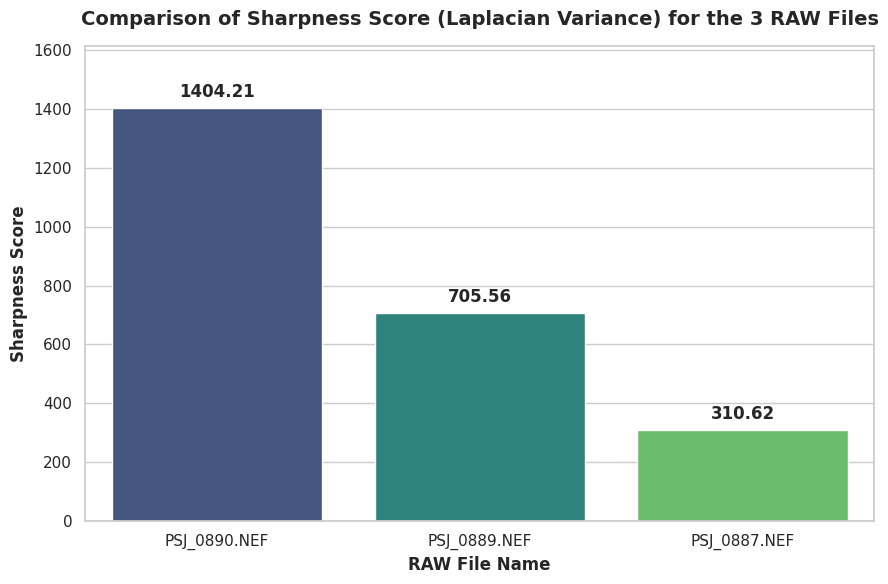

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'df_comparison' in globals() and not df_comparison.empty:
    plt.figure(figsize=(9, 6))
    sns.set_theme(style="whitegrid")

    # สร้างกราฟแท่งเปรียบเทียบคะแนนความคมชัด
    ax = sns.barplot(
        data=df_comparison,
        x='File Name',
        y='Sharpness Score',
        hue='File Name',
        palette='viridis',
        legend=False
    )

    # ใส่ตัวเลขคะแนนความคมชัดบนแต่ละเสาของกราฟแท่ง
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', fontweight='bold', label_type='edge', padding=5)

    plt.title('Comparison of Sharpness Score (Laplacian Variance) for the 3 RAW Files', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('RAW File Name', fontsize=12, fontweight='bold')
    plt.ylabel('Sharpness Score', fontsize=12, fontweight='bold')

    # ปรับปรุงขอบเขตแกน Y เพื่อป้องกันไม่ให้ตัวเลขคะแนนชนขอบด้านบน
    plt.ylim(0, df_comparison['Sharpness Score'].max() * 1.15)

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ ไม่พบข้อมูลคะแนนความคมชัดในระบบ กรุณารันเซลล์วิเคราะห์ก่อนหน้านี้เพื่อคำนวณคะแนนก่อนครับ")

In [21]:
import pandas as pd
import numpy as np
import exiftool

# โหลดข้อมูล metadata ทั้งหมดของทั้ง 3 ไฟล์
files_to_analyze = ['PSJ_0887.NEF', 'PSJ_0889.NEF', 'PSJ_0890.NEF']
raw_metadata = []

with exiftool.ExifToolHelper() as et:
    for f in files_to_analyze:
        meta = et.get_metadata(f)[0]
        raw_metadata.append(meta)

# แปลงเป็น DataFrame
df_all_meta = pd.DataFrame(raw_metadata)

# เลือกเฉพาะคอลัมน์ที่เป็นตัวเลขเพื่อนำมาวิเคราะห์ทางสถิติ
numeric_cols = df_all_meta.select_dtypes(include=[np.number]).columns

# กรองหาคอลัมน์ที่มีค่าแปรผัน (Variance > 0) ระหว่าง 3 ภาพนี้
varied_features = []
for col in numeric_cols:
    # เช็คว่าไม่มีค่า NaN
    if not df_all_meta[col].isnull().any():
        std_val = df_all_meta[col].std()
        if std_val > 0:
            varied_features.append({
                'Metadata Tag': col,
                'PSJ_0887.NEF': df_all_meta.loc[df_all_meta['File:FileName'] == 'PSJ_0887.NEF', col].values[0],
                'PSJ_0889.NEF': df_all_meta.loc[df_all_meta['File:FileName'] == 'PSJ_0889.NEF', col].values[0],
                'PSJ_0890.NEF': df_all_meta.loc[df_all_meta['File:FileName'] == 'PSJ_0890.NEF', col].values[0],
                'Std Dev': round(std_val, 4)
            })

df_varied = pd.DataFrame(varied_features)

print("📊 รายการแท็กประเภทตัวเลขที่มีความผันแปรหรือผิดปกติในแต่ละรูปภาพ (Sorted by Std Dev):")
if not df_varied.empty:
    display(df_varied.sort_values(by='Std Dev', ascending=False).reset_index(drop=True))
else:
    print("✅ ไม่พบความผิดปกติหรือความผันแปรในข้อมูลเชิงตัวเลขของอภิข้อมูลเลย ทุกค่าเท่ากันทั้งหมด!")

📊 รายการแท็กประเภทตัวเลขที่มีความผันแปรหรือผิดปกติในแต่ละรูปภาพ (Sorted by Std Dev):


,Metadata Tag,PSJ_0887.NEF,PSJ_0889.NEF,PSJ_0890.NEF,Std Dev
0,File:FileSize,4.417159e+07,4.487985e+07,4.533381e+07,585727.6760
1,EXIF:StripOffsets,3.741184e+06,4.175872e+06,4.441088e+06,353355.0606
2,EXIF:JpgFromRawLength,2.562278e+06,2.949369e+06,3.198252e+06,320480.1394
3,EXIF:StripByteCounts,4.043041e+07,4.070398e+07,4.089272e+07,232450.6651
4,EXIF:JpgFromRawStart,1.178624e+06,1.226240e+06,1.242624e+06,33245.8491
5,EXIF:OtherImageLength,9.373260e+05,9.805060e+05,1.001689e+06,32802.0011
6,MakerNotes:PreviewImageLength,1.381020e+05,1.421480e+05,1.371620e+05,2649.3368
7,EXIF:OtherImageStart,2.411520e+05,2.452480e+05,2.406400e+05,2525.6360
8,EXIF:SubSecTime,2.600000e+01,9.200000e+01,2.600000e+01,38.1051
9,EXIF:SubSecTimeOriginal,2.600000e+01,9.200000e+01,2.600000e+01,38.1051


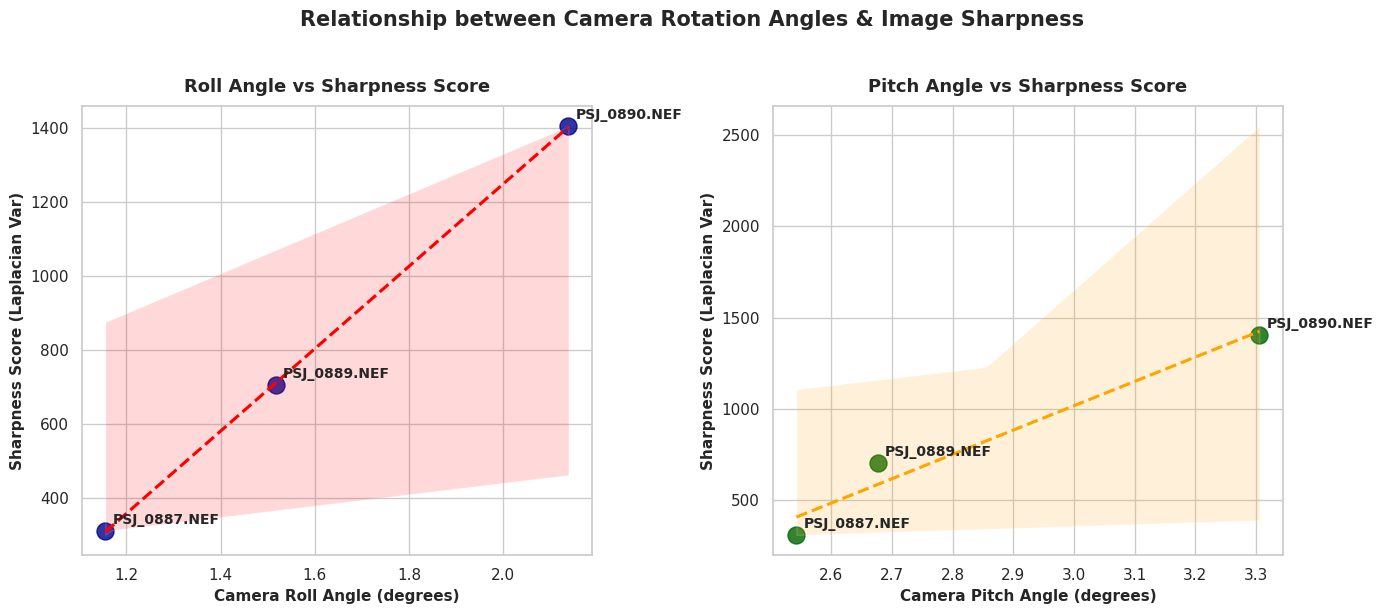

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

if 'df_comparison' in globals() and 'df_all_meta' in globals():
    # ดึงค่ามุมกล้อง (Roll/Pitch) และชื่อไฟล์จาก df_all_meta
    df_angles = df_all_meta[['File:FileName', 'MakerNotes:RollAngle', 'MakerNotes:PitchAngle']].copy()
    df_angles.rename(columns={'File:FileName': 'File Name', 'MakerNotes:RollAngle': 'Roll Angle', 'MakerNotes:PitchAngle': 'Pitch Angle'}, inplace=True)

    # รวมข้อมูลกับ df_comparison เพื่อดึงคะแนนความคมชัด
    df_plot = pd.merge(df_comparison, df_angles, on='File Name')

    # ตั้งค่าธีมการพล็อต
    sns.set_theme(style="whitegrid")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # 1. พล็อตกราฟแสดงความสัมพันธ์ระหว่าง Roll Angle (มุมเอียงซ้าย-ขวา) กับ Sharpness Score
    sns.regplot(data=df_plot, x='Roll Angle', y='Sharpness Score', ax=ax1,
                scatter_kws={'s': 150, 'color': 'darkblue'}, line_kws={'color': 'red', 'linestyle': '--'})
    for i, txt in enumerate(df_plot['File Name']):
        ax1.annotate(txt, (df_plot['Roll Angle'].iloc[i], df_plot['Sharpness Score'].iloc[i]),
                     xytext=(5, 5), textcoords='offset points', fontsize=10, fontweight='bold')
    ax1.set_title('Roll Angle vs Sharpness Score', fontsize=13, fontweight='bold', pad=10)
    ax1.set_xlabel('Camera Roll Angle (degrees)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Sharpness Score (Laplacian Var)', fontsize=11, fontweight='bold')

    # 2. พล็อตกราฟแสดงความสัมพันธ์ระหว่าง Pitch Angle (มุมก้ม-เงย) กับ Sharpness Score
    sns.regplot(data=df_plot, x='Pitch Angle', y='Sharpness Score', ax=ax2,
                scatter_kws={'s': 150, 'color': 'darkgreen'}, line_kws={'color': 'orange', 'linestyle': '--'})
    for i, txt in enumerate(df_plot['File Name']):
        ax2.annotate(txt, (df_plot['Pitch Angle'].iloc[i], df_plot['Sharpness Score'].iloc[i]),
                     xytext=(5, 5), textcoords='offset points', fontsize=10, fontweight='bold')
    ax2.set_title('Pitch Angle vs Sharpness Score', fontsize=13, fontweight='bold', pad=10)
    ax2.set_xlabel('Camera Pitch Angle (degrees)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Sharpness Score (Laplacian Var)', fontsize=11, fontweight='bold')

    plt.suptitle('Relationship between Camera Rotation Angles & Image Sharpness', fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ ไม่พบข้อมูลความคมชัดหรือข้อมูลอภิข้อมูลของมุมกล้องในหน่วยความจำ กรุณารันเซลล์วิเคราะห์ก่อนหน้านี้")

In [23]:
import os
import glob
import cv2
import rawpy
import numpy as np
import pandas as pd
import exiftool
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import files

# --- 1. ฐานข้อมูลยี่ห้อและรุ่นของกล้องและเลนส์เพื่อใช้เปรียบเทียบ/ระบุ (Database) ---
camera_lens_db = {
    "Brands": ["Nikon", "Canon", "Sigma", "Tamron", "Samyang", "Tokina"],
    "Dslr_Models": [
        "NIKON D810", "NIKON D850", "NIKON D750", "NIKON D500",
        "Canon EOS 5D Mark IV", "Canon EOS 6D Mark II", "Canon EOS 90D"
    ]
}

# --- ตัวแปรโกลบอลสำหรับจัดเก็บ UI Outputs ---
output_area = widgets.Output()

# --- ฟังก์ชันช่วยสกัด Metadata ละเอียดสำหรับหนึ่งไฟล์ ---
def extract_detailed_metadata(file_path):
    try:
        with exiftool.ExifToolHelper() as et:
            meta = et.get_metadata(file_path)[0]

        # ตรวจสอบและสกัดชื่อกล้องและเลนส์
        camera = meta.get("EXIF:Model", "Unknown Camera")
        lens = meta.get("MakerNotes:LensSpec", meta.get("EXIF:LensModel", "Unknown Lens"))

        # การแยกข้อมูลทางกายภาพอื่น ๆ
        iso = meta.get("EXIF:ISO", "N/A")
        aperture = meta.get("EXIF:FNumber", "N/A")
        shutter = meta.get("EXIF:ExposureTime", "N/A")
        focal = meta.get("EXIF:FocalLength", "N/A")

        return {
            "File Name": os.path.basename(file_path),
            "Camera": camera,
            "Lens": lens,
            "ISO": iso,
            "Aperture": f"f/{aperture}" if aperture != "N/A" else "N/A",
            "Shutter Speed": f"{shutter}s" if shutter != "N/A" else "N/A",
            "Focal Length": f"{focal}mm" if focal != "N/A" else "N/A",
            "meta_full": meta
        }
    except Exception as e:
        return {"File Name": os.path.basename(file_path), "Error": str(e)}

# --- ฟังก์ชันคำนวณ Sharpness และขอบสำหรับเมนูที่ 1 ---
def analyze_single_file(file_path):
    with rawpy.imread(file_path) as raw:
        rgb_image = raw.postprocess(half_size=True)
    gray = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
    h, w = gray.shape

    meta_info = extract_detailed_metadata(file_path)
    meta = meta_info.get("meta_full", {})

    af_w = meta.get("MakerNotes:AFImageWidth", w*2)
    af_h = meta.get("MakerNotes:AFImageHeight", h*2)
    af_x = meta.get("MakerNotes:AFAreaXPosition", None)
    af_y = meta.get("MakerNotes:AFAreaYPosition", None)

    if af_x is not None and af_y is not None:
        scale_x = w / float(af_w)
        scale_y = h / float(af_h)
        cx, cy = int(af_x * scale_x), int(af_y * scale_y)
    else:
        cx, cy = w // 2, h // 2

    min_dim = min(h, w)
    box_size = int(min_dim * 0.15)
    if box_size % 2 != 0: box_size += 1
    half_box = box_size // 2

    sx, ex = max(0, cx - half_box), min(w, cx + half_box)
    sy, ey = max(0, cy - half_box), min(h, cy + half_box)

    roi = gray[sy:ey, sx:ex]
    roi_rgb = rgb_image[sy:ey, sx:ex]
    score = np.var(cv2.Laplacian(roi, cv2.CV_64F))

    return rgb_image, roi_rgb, score, cx, cy, sx, sy, ex, ey, meta_info

# --- 2. การทำงานหลักของปุ่มควบคุม (Event Handlers) ---
def on_menu1_clicked(b):
    with output_area:
        clear_output()
        nef_files = sorted(glob.glob("*.NEF") + glob.glob("*.nef"))
        if not nef_files:
            print("⚠️ ไม่พบไฟล์ภาพ RAW (.NEF) ในระบบ กรุณาอัปโหลดก่อน")
            return

        print("📊 รายการไฟล์ RAW ที่พร้อมทดสอบ:")
        for idx, f in enumerate(nef_files):
            print(f" [{idx}] {f}")

        # วิเคราะห์ภาพแรกในลิสต์เป็นต้นแบบการทดสอบ
        target_file = nef_files[0]
        print(f"\n🔍 กำลังประมวลผลไฟล์ทดสอบหลัก: {target_file}")

        rgb, roi, score, cx, cy, sx, sy, ex, ey, info = analyze_single_file(target_file)

        # แสดงผลภาพถ่ายย่อและกล่องโฟกัส
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
        ax1.imshow(rgb)
        rect = patches.Rectangle((sx, sy), ex - sx, ey - sy, linewidth=2, edgecolor='cyan', facecolor='none')
        ax1.add_patch(rect)
        ax1.scatter(cx, cy, color='red', marker='+', s=100, label='AF Center')
        ax1.set_title(f"{target_file} - Scaled AF Box")
        ax1.legend()
        ax1.axis('off')

        ax2.imshow(roi)
        ax2.set_title(f"ROI Focus Area\nSharpness: {score:.2f}")
        ax2.axis('off')
        plt.tight_layout()
        plt.show()

        # สรุปรายละเอียด
        print("\n📋 รายละเอียด Metadata ที่สกัดได้จากไฟล์นี้:")
        for k, v in info.items():
            if k != "meta_full":
                print(f"   ▶ {k}: {v}")

def on_menu2_clicked(b):
    with output_area:
        clear_output()
        nef_files = sorted(glob.glob("*.NEF") + glob.glob("*.nef"))
        if not nef_files:
            print("⚠️ ไม่พบไฟล์ภาพ RAW (.NEF) ในระบบ")
            return

        print(f"⚙️ เริ่มระบบวิเคราะห์สกัดคุณลักษณะครอบคลุมข้อมูลทั้งหมด ({len(nef_files)} ไฟล์)...\n")
        records = []
        for file_path in nef_files:
            _, _, score, _, _, _, _, _, _, info = analyze_single_file(file_path)
            info["Sharpness Score"] = round(score, 2)
            records.append(info)

        df = pd.DataFrame(records)
        # ลบข้อมูลที่เก็บดิบออกเพื่อแสดงตารางสวยงาม
        display_cols = ["File Name", "Camera", "Lens", "ISO", "Aperture", "Shutter Speed", "Focal Length", "Sharpness Score"]
        display(df[display_cols])

        # วาดกราฟเปรียบเทียบรวม
        plt.figure(figsize=(10, 5))
        sns.barplot(data=df, x='File Name', y='Sharpness Score', hue='File Name', palette='magma', legend=False)
        plt.title('Batch Comparison of Image Sharpness Scores', fontsize=12, fontweight='bold')
        plt.xlabel('RAW File Name')
        plt.ylabel('Sharpness Score')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.show()

# --- 3. การสร้างและจัดรูปเลย์เอาต์หน้าต่าง แดชบอร์ด (Dashboard UI) ---
btn_menu1 = widgets.Button(
    description="1. ทดสอบตรวจค่าภาพเดี่ยว",
    button_style="primary",
    icon="image",
    layout=widgets.Layout(width='280px', margin='10px')
)
btn_menu2 = widgets.Button(
    description="2. ประมวลผลเปรียบเทียบกลุ่มภาพ",
    button_style="success",
    icon="bar-chart",
    layout=widgets.Layout(width='280px', margin='10px')
)

btn_menu1.on_click(on_menu1_clicked)
btn_menu2.on_click(on_menu2_clicked)

header = widgets.HTML(
    "<h2 style='text-align: center; color: #2C3E50;'>RAW Focus & Sharpness Analytics Dashboard</h2>"
    "<p style='text-align: center; color: #7F8C8D;'>ระบบตรวจสอบและประเมินคุณภาพภาพถ่ายสำหรับกล้องถ่ายรูป DSLR (Nikon / Canon)</p>"
)

menu_layout = widgets.HBox([btn_menu1, btn_menu2], layout=widgets.Layout(justify_content='center'))
dashboard = widgets.VBox([header, menu_layout, output_area])

# แสดงผล Dashboard
display(dashboard)

In [35]:
%%writefile main.py
import streamlit as st
import os
import json
import cv2
import rawpy
import numpy as np
import pandas as pd
import exiftool
import tempfile
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import io

# --- ตั้งค่าหน้าเว็บ Streamlit ---
st.set_page_config(
    page_title="RAW Image Analytics Dashboard",
    page_icon="📸",
    layout="wide"
)

# --- 1. จัดการระบบฐานข้อมูลกล้องและเลนส์จากไฟล์ JSON (Persistent Storage) ---
DB_FILE = 'camera_db.json'

def load_camera_db():
    default_db = {
        "Brands": ["Nikon", "Canon", "Sigma", "Tamron", "Samyang", "Tokina"],
        "Models": ["NIKON D810", "NIKON D850", "NIKON D750", "Canon EOS 5D Mark IV", "Canon EOS 6D Mark II"]
    }
    if os.path.exists(DB_FILE):
        try:
            with open(DB_FILE, 'r', encoding='utf-8') as f:
                return json.load(f)
        except Exception:
            return default_db
    return default_db

def save_camera_db(db_data):
    try:
        with open(DB_FILE, 'w', encoding='utf-8') as f:
            json.dump(db_data, f, indent=2, ensure_ascii=False)
        return True
    except Exception:
        return False

# โหลดข้อมูลเข้าสู่ Session State
if 'camera_db' not in st.session_state:
    st.session_state['camera_db'] = load_camera_db()

# --- 2. ฟังก์ชันช่วยประมวลผลสกัดอภิข้อมูลเชิงลึก ---
def extract_metadata_from_bytes(file_bytes, filename):
    with tempfile.NamedTemporaryFile(delete=False, suffix=os.path.splitext(filename)[1]) as temp_file:
        temp_file.write(file_bytes)
        temp_path = temp_file.name

    try:
        with exiftool.ExifToolHelper() as et:
            meta = et.get_metadata(temp_path)[0]

        # สกัดข้อมูลเชิงลึก
        camera = meta.get("EXIF:Model", "Unknown Camera")
        lens = meta.get("MakerNotes:LensSpec", meta.get("EXIF:LensModel", "Unknown Lens"))
        iso = meta.get("EXIF:ISO", "N/A")
        aperture = meta.get("EXIF:FNumber", "N/A")
        shutter = meta.get("EXIF:ExposureTime", "N/A")
        focal = meta.get("EXIF:FocalLength", "N/A")
        focus_mode = meta.get("MakerNotes:FocusMode", "N/A")
        af_area_mode = meta.get("MakerNotes:AFAreaMode", "N/A")
        focus_distance = meta.get("MakerNotes:FocusDistance", "N/A")

        return {
            "File Name": filename,
            "Camera": camera,
            "Lens": lens,
            "ISO": iso,
            "Aperture": f"f/{aperture}" if aperture != "N/A" else "N/A",
            "Shutter Speed": f"{shutter}s" if shutter != "N/A" else "N/A",
            "Focal Length": f"{focal}mm" if focal != "N/A" else "N/A",
            "Focus Mode": focus_mode,
            "AF Area Mode": af_area_mode,
            "Focus Distance (m)": focus_distance,
            "meta_full": meta
        }, temp_path
    except Exception as e:
        return {"File Name": filename, "Error": str(e)}, temp_path

def analyze_raw_file(temp_path, meta_info):
    try:
        with rawpy.imread(temp_path) as raw:
            # ดึงภาพ thumbnail (ถ้ามี) หรือ postprocess แบบ half_size
            try:
                thumb = raw.extract_thumb()
                if thumb.format == rawpy.ThumbFormat.JPEG:
                    thumb_img = Image.open(io.BytesIO(thumb.data))
                else:
                    thumb_img = Image.fromarray(thumb.data)
            except rawpy.LibRawNoThumbnailError:
                thumb_img = None

            rgb_image = raw.postprocess(half_size=True)

        gray = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
        h, w = gray.shape

        meta = meta_info.get("meta_full", {})
        af_w = meta.get("MakerNotes:AFImageWidth", w*2)
        af_h = meta.get("MakerNotes:AFImageHeight", h*2)
        af_x = meta.get("MakerNotes:AFAreaXPosition", None)
        af_y = meta.get("MakerNotes:AFAreaYPosition", None)

        if af_x is not None and af_y is not None:
            scale_x = w / float(af_w)
            scale_y = h / float(af_h)
            cx, cy = int(af_x * scale_x), int(af_y * scale_y)
        else:
            cx, cy = w // 2, h // 2

        min_dim = min(h, w)
        box_size = int(min_dim * 0.15)
        if box_size % 2 != 0:
            box_size += 1
        half_box = box_size // 2

        sx, ex = max(0, cx - half_box), min(w, cx + half_box)
        sy, ey = max(0, cy - half_box), min(h, cy + half_box)

        roi = gray[sy:ey, sx:ex]
        roi_rgb = rgb_image[sy:ey, sx:ex]
        score = np.var(cv2.Laplacian(roi, cv2.CV_64F))

        return rgb_image, roi_rgb, score, cx, cy, sx, sy, ex, ey, thumb_img
    except Exception as e:
        return None, None, 0, 0, 0, 0, 0, 0, 0, None

# --- 3. ส่วนหัวของเว็บไซต์ (Header UI) ---
st.title("📸 RAW Focus & Sharpness Analytics Dashboard")
st.write("ระบบสกัดและวิเคราะห์คุณภาพความคมชัดของภาพจากระบบจุดโฟกัสกล้อง DSLR (Canon/Nikon) บนเว็บแอปพลิเคชัน")

# --- 4. เมนูแถบด้านข้างสำหรับควบคุมฐานข้อมูล (Sidebar Database Manager) ---
with st.sidebar:
    st.header("⚙️ ตั้งค่าฐานข้อมูลอุปกรณ์")
    st.write("จัดการฐานข้อมูลแบรนด์กล้องและเลนส์ที่รองรับในระบบถาวร (JSON Database)")

    new_brand = st.text_input("➕ เพิ่มยี่ห้อกล้อง/เลนส์ (เช่น Tamron, Sigma):")
    if st.button("บันทึกยี่ห้อ") and new_brand:
        if new_brand not in st.session_state['camera_db']["Brands"]:
            st.session_state['camera_db']["Brands"].append(new_brand)
            if save_camera_db(st.session_state['camera_db']):
                st.success(f"เพิ่มยี่ห้อ '{new_brand}' และบันทึกลง JSON แล้ว!")
            else:
                st.error("ไม่สามารถบันทึกฐานข้อมูลลงไฟล์ได้")

    new_model = st.text_input("➕ เพิ่มรุ่นกล้องถ่ายภาพ DSLR:")
    if st.button("บันทึกรุ่นกล้อง") and new_model:
        if new_model not in st.session_state['camera_db']["Models"]:
            st.session_state['camera_db']["Models"].append(new_model)
            if save_camera_db(st.session_state['camera_db']):
                st.success(f"เพิ่มรุ่นกล้อง '{new_model}' ลงระบบถาวรแล้ว!")
            else:
                st.error("ไม่สามารถบันทึกฐานข้อมูลลงไฟล์ได้")

    st.subheader("📂 ข้อมูลปัจจุบันในระบบ")
    st.write("**แบรนด์ที่รองรับ:**", ", ".join(st.session_state['camera_db']["Brands"]))
    st.write("**รุ่นกล้องที่ลงทะเบียน:**", ", ".join(st.session_state['camera_db']["Models"]))

# --- 5. แท็บสำหรับการทำงานหลัก 2 เมนู (Dashboard Navigation Tabs) ---
tab1, tab2 = st.tabs(["🔍 1. ทดสอบตรวจค่าภาพเดี่ยว", "📊 2. ประมวลผลเปรียบเทียบกลุ่มภาพ"])

# --- เมนู 1: ทดสอบตรวจสอบภาพเดี่ยว ---
with tab1:
    st.header("🔍 วิเคราะห์ข้อมูลและจำลองกรอบพิกัด AF อ้างอิงรายไฟล์")
    uploaded_file = st.file_uploader("กรุณาอัปโหลดภาพ RAW (.NEF)", type=["nef"], key="single_file")

    if uploaded_file is not None:
        file_bytes = uploaded_file.read()
        with st.spinner("กำลังวิเคราะห์ไฟล์ภาพ RAW โปรดรอสักครู่..."):
            meta_info, temp_path = extract_metadata_from_bytes(file_bytes, uploaded_file.name)

            if "Error" in meta_info:
                st.error(f"เกิดข้อผิดพลาดในการอ่านไฟล์: {meta_info['Error']}")
            else:
                rgb, roi, score, cx, cy, sx, sy, ex, ey, thumb_img = analyze_raw_file(temp_path, meta_info)

                # แสดงผลแบ่งเป็น 3 คอลัมน์สำหรับรูปภาพ
                col_t, col1, col2 = st.columns([1, 2, 2])

                with col_t:
                    st.subheader("🖼️ ภาพย่อ (Thumbnail)")
                    if thumb_img:
                        st.image(thumb_img, use_container_width=True)
                    else:
                        st.info("ไม่มี Thumbnail ฝังอยู่ในไฟล์นี้")

                with col1:
                    st.subheader("🖼️ รูปถ่ายต้นฉบับย่อส่วนพร้อมกรอบโฟกัส")
                    fig1, ax1 = plt.subplots(figsize=(6, 4.5))
                    ax1.imshow(rgb)
                    rect = patches.Rectangle((sx, sy), ex-sx, ey-sy, linewidth=2, edgecolor='cyan', facecolor='none')
                    ax1.add_patch(rect)
                    ax1.scatter(cx, cy, color='red', marker='+', s=100, label='AF Center')
                    ax1.legend()
                    ax1.axis('off')
                    st.pyplot(fig1)

                with col2:
                    st.subheader("🎯 พื้นที่ตรวจสอบความคมชัดเฉพาะจุด (ROI)")
                    fig2, ax2 = plt.subplots(figsize=(6, 4.5))
                    ax2.imshow(roi)
                    ax2.set_title(f"Sharpness (Laplacian Var): {score:.2f}")
                    ax2.axis('off')
                    st.pyplot(fig2)

                # แสดงรายละเอียดเชิงลึก
                st.subheader("📋 สรุปรายละเอียดอภิข้อมูลอุปกรณ์ (Detailed EXIF Metadata)")

                # แบ่งข้อมูลเป็น 2 ตารางเพื่อความสวยงาม
                col_detail1, col_detail2 = st.columns(2)

                with col_detail1:
                    st.markdown("**ข้อมูลอุปกรณ์พื้นฐาน**")
                    meta_basic = {
                        "ชื่อไฟล์": meta_info.get("File Name", ""),
                        "กล้องถ่ายภาพ": meta_info.get("Camera", ""),
                        "เลนส์ที่ใช้": meta_info.get("Lens", ""),
                    }
                    st.table(pd.DataFrame(list(meta_basic.items()), columns=["คุณสมบัติ", "ค่าที่ได้"]))

                with col_detail2:
                    st.markdown("**การตั้งค่าการถ่ายภาพ (Settings & AF)**")
                    meta_settings = {
                        "ISO": meta_info.get("ISO", ""),
                        "รูรับแสง": meta_info.get("Aperture", ""),
                        "สปีดชัตเตอร์": meta_info.get("Shutter Speed", ""),
                        "ความยาวโฟกัส": meta_info.get("Focal Length", ""),
                        "โหมดโฟกัส": meta_info.get("Focus Mode", ""),
                        "โหมดพื้นที่ AF": meta_info.get("AF Area Mode", ""),
                        "ระยะโฟกัส (เมตร)": meta_info.get("Focus Distance (m)", "")
                    }
                    st.table(pd.DataFrame(list(meta_settings.items()), columns=["การตั้งค่า", "ค่าที่ได้"]))

            # ทำลายไฟล์ชั่วคราว
            if os.path.exists(temp_path):
                os.remove(temp_path)

# --- เมนู 2: เปรียบเทียบสถิติกลุ่มภาพ ---
with tab2:
    st.header("📊 วิเคราะห์และสรุปผลข้อมูลเชิงเปรียบเทียบในรูปภาพหลายไฟล์")
    uploaded_files = st.file_uploader("กรุณาอัปโหลดกลุ่มภาพ RAW (.NEF) เพื่อทำการเปรียบเทียบ", type=["nef"], accept_multiple_files=True, key="multi_file")

    if uploaded_files:
        records = []
        for f_upload in uploaded_files:
            file_bytes = f_upload.read()
            meta_info, temp_path = extract_metadata_from_bytes(file_bytes, f_upload.name)

            if "Error" not in meta_info:
                _, _, score, _, _, _, _, _, _, _ = analyze_raw_file(temp_path, meta_info)
                meta_info["Sharpness Score"] = round(score, 2)
                records.append(meta_info)

            if os.path.exists(temp_path):
                os.remove(temp_path)

        if records:
            df = pd.DataFrame(records)

            st.subheader("📈 ตารางสรุปการประเมินวิเคราะห์ผลเชิงสถิติ (พร้อมข้อมูลการตั้งค่ากล้องเชิงลึก)")
            display_cols = ["File Name", "Camera", "Lens", "ISO", "Aperture", "Shutter Speed", "Focal Length", "Focus Mode", "Focus Distance (m)", "Sharpness Score"]
            st.dataframe(df[display_cols], use_container_width=True)

            st.subheader("📊 แผนภูมิแท่งเปรียบเทียบคะแนนความคมชัด (Sharpness Variance)")
            fig_bar, ax_bar = plt.subplots(figsize=(10, 4.5))
            ax_bar.bar(df["File Name"], df["Sharpness Score"], color='#3498DB', alpha=0.85, width=0.4)
            ax_bar.set_title("Sharpness Quality Assessment (Higher is Sharper)", fontsize=12, fontweight='bold')
            ax_bar.set_ylabel("Sharpness Score (Laplacian Var)")
            ax_bar.grid(axis='y', linestyle='--', alpha=0.5)
            st.pyplot(fig_bar)
        else:
            st.warning("⚠️ ไม่สามารถวิเคราะห์สกัดคุณสมบัติไฟล์ที่อัปโหลดได้")


Writing main.py


In [25]:
%%writefile requirements.txt
streamlit
rawpy
opencv-python-headless
pyexiftool
matplotlib
pandas
numpy

Writing requirements.txt


In [26]:
%%writefile apt.txt
libimage-exiftool-perl

Writing apt.txt


In [27]:
%%writefile camera_db.json
{
  "Brands": ["Nikon", "Canon", "Sigma", "Tamron", "Samyang", "Tokina"],
  "Models": ["NIKON D810", "NIKON D850", "NIKON D750", "Canon EOS 5D Mark IV", "Canon EOS 6D Mark II"]
}

Writing camera_db.json


In [28]:
import json

# อ่านและแสดงผลโครงสร้างข้อมูลภายในไฟล์ camera_db.json
with open('camera_db.json', 'r', encoding='utf-8') as f:
    db_content = json.load(f)

print(json.dumps(db_content, indent=2, ensure_ascii=False))

{
  "Brands": [
    "Nikon",
    "Canon",
    "Sigma",
    "Tamron",
    "Samyang",
    "Tokina"
  ],
  "Models": [
    "NIKON D810",
    "NIKON D850",
    "NIKON D750",
    "Canon EOS 5D Mark IV",
    "Canon EOS 6D Mark II"
  ]
}


In [32]:
import os
import json

def load_camera_db(file_path='camera_db.json'):
    # กำหนดค่าเริ่มต้นกรณีที่ไม่พบไฟล์
    default_db = {
        "Brands": ["Nikon", "Canon"],
        "Models": ["N/A"]
    }

    if os.path.exists(file_path):
        try:
            with open(file_path, 'r', encoding='utf-8') as f:
                data = json.load(f)
                print("✅ โหลดไฟล์ฐานข้อมูลสำเร็จ!")
                return data
        except Exception as e:
            print(f"⚠️ เกิดข้อผิดพลาดในการอ่านไฟล์: {e} (กำลังใช้ค่าเริ่มต้นแทน)")
            return default_db
    else:
        print("⚠️ ไม่พบไฟล์ฐานข้อมูล (กำลังใช้ค่าเริ่มต้นแทน)")
        return default_db

# ทดสอบดึงข้อมูล
camera_data = load_camera_db()
print("\n--- ข้อมูลที่อ่านได้ ---")
print("ยี่ห้อกล้อง/เลนส์ในระบบ:", camera_data.get("Brands", []))
print("รุ่นกล้องที่รองรับในระบบ:", camera_data.get("Models", []))

✅ โหลดไฟล์ฐานข้อมูลสำเร็จ!

--- ข้อมูลที่อ่านได้ ---
ยี่ห้อกล้อง/เลนส์ในระบบ: ['Nikon', 'Canon', 'Sigma', 'Tamron', 'Samyang', 'Tokina']
รุ่นกล้องที่รองรับในระบบ: ['NIKON D810', 'NIKON D850', 'NIKON D750', 'Canon EOS 5D Mark IV', 'Canon EOS 6D Mark II']


In [36]:
import urllib

# ดึงหมายเลข IP เพื่อใช้เป็นรหัสผ่าน (Endpoint IP) สำหรับ localtunnel
print("🔑 รหัสผ่านสำหรับกรอกในหน้าเว็บ localtunnel คือ:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip("\n"))

# รัน Streamlit แบบ Background process
!streamlit run main.py &>/content/logs.txt &

# ใช้ localtunnel เพื่อสร้าง Public URL (เพิ่ม -y เพื่อยืนยันการติดตั้งอัตโนมัติ)
!npx -y localtunnel --port 8501


🔑 รหัสผ่านสำหรับกรอกในหน้าเว็บ localtunnel คือ: 34.182.58.192
⠙⠹⠸⠼your url is: https://slimy-cobras-float.loca.lt
^C
